In [31]:
import pandas as pd

In [32]:
titanic = pd.read_csv('data/titanic.csv')
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [33]:

titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [34]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [35]:
titanic.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [36]:
titanic['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

<Axes: xlabel='Age'>

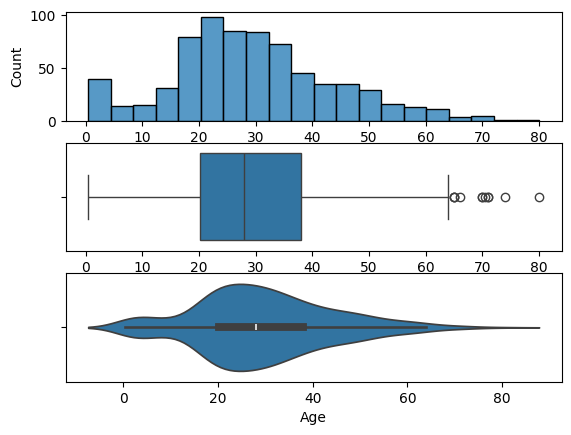

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.subplot(3,1,1)
sns.histplot (data = titanic, x = 'Age')
plt.subplot(3,1,2)
sns.boxplot(data = titanic, x = 'Age')
plt.subplot(3,1,3)
sns.violinplot(data = titanic, x = 'Age')

In [38]:
titanic['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [39]:
#이상치 판단
# IQR
IQR = titanic['Age'].quantile(0.75) - titanic['Age'].quantile(0.25)
high_border = titanic['Age'].quantile(0.75) + IQR * 1.5
low_border = titanic['Age'].quantile(0.25) - IQR * 1.5
print( high_border , low_border )

64.8125 -6.6875


[7.9104 0.    ]
[31. 65.]


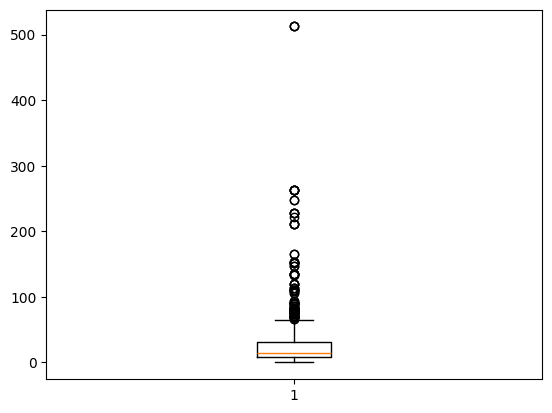

In [43]:

box = plt.boxplot(titanic['Fare'])
print(box['whiskers'][0].get_ydata())
print(box['whiskers'][1].get_ydata())

<Axes: xlabel='Fare'>

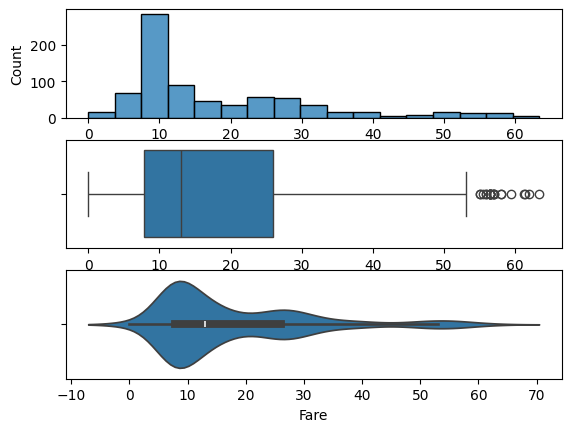

In [44]:
titanic2 = titanic[(titanic['Fare'] < high_border ) & (titanic['Fare'] > low_border)]
plt.subplot(3,1,1)
sns.histplot(data = titanic2, x = 'Fare')
plt.subplot(3,1,2)
sns.boxplot(data = titanic2, x = 'Fare')
plt.subplot(3,1,3)
sns.violinplot(data = titanic2, x = 'Fare')

In [41]:
titanic[titanic['Fare'] < 65.6344 ]['Fare'].max()

np.float64(65.0)

In [ ]:
#이상치 판단
#zscore : 평균에서 떨어진 정도로 이상치 검출 , 2~3 의 값으로 검출
import numpy as np
z_score = np.abs(titanic['Fare'] - titanic['Fare'].mean()) / titanic['Fare'].std()
titanic3 = titanic[z_score < 2.5]

<Axes: xlabel='Fare'>

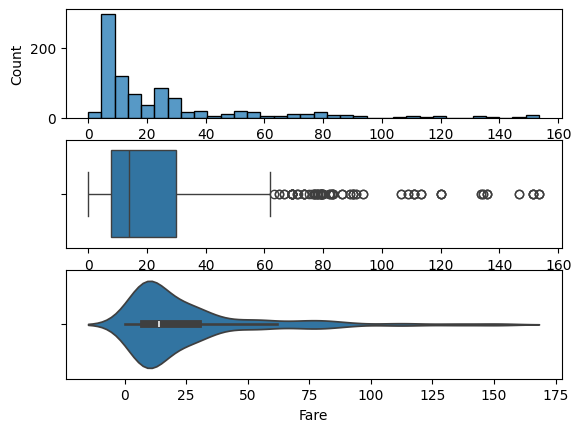

In [48]:
plt.subplot(3,1,1)
sns.histplot(data = titanic3, x = 'Fare')
plt.subplot(3,1,2)
sns.boxplot(data = titanic3, x = 'Fare')
plt.subplot(3,1,3)
sns.violinplot(data = titanic3, x = 'Fare')

In [52]:
titanic['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [53]:
titanic['Sex'].describe()

count      891
unique       2
top       male
freq       577
Name: Sex, dtype: object

In [55]:
titanic['Pclass'].unique()

array([3, 1, 2])

([<matplotlib.patches.Wedge at 0x174e9488260>,
 [Text(-0.17571619097547903, 1.085874679799225, '3'),
  Text(-0.5160760536623383, -0.9714244730478574, '1'),
  Text(0.8765111790709129, -0.6646263258130227, '2')],
 [Text(-0.09584519507753402, 0.5922952798904862, '55.11%'),
  Text(-0.2814960292703663, -0.5298678943897404, '24.24%'),
  Text(0.47809700676595246, -0.3625234504434669, '20.65%')])

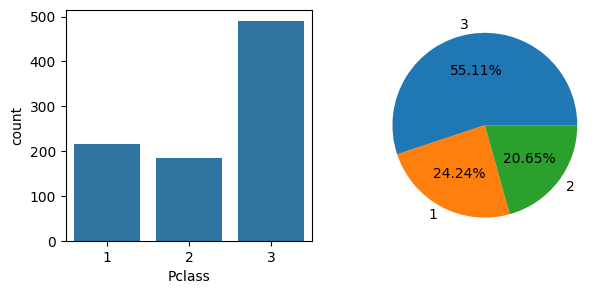

In [56]:
p_cnt = titanic['Pclass'].value_counts()
plt.figure(figsize = (7,3))
plt.subplot(1,2,1)
sns.countplot(data = titanic, x = 'Pclass')
plt.subplot(1,2,2)
plt.pie(p_cnt.values , labels = p_cnt.index , autopct = '%.2f%%')

In [60]:
air = pd.read_csv('data/ozone.csv')
air.head()

,Ozone,Solar.R,Wind,Temp,Date
0,41,190.0,7.4,67,1973-05-01
1,36,118.0,8.0,72,1973-05-02
2,12,149.0,12.6,74,1973-05-03
3,18,313.0,11.5,62,1973-05-04
4,19,NaN,14.3,56,1973-05-05


<Axes: xlabel='Temp', ylabel='Ozone'>

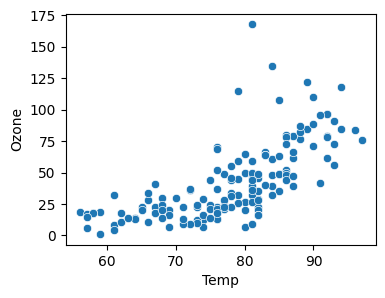

In [65]:
plt.figure(figsize=(4,3))
sns.scatterplot(x= 'Temp',y= 'Ozone',data= air)